# 02 — Análise exploratória de dados (dataset *tiny*)

Este notebook explora o dataset `tiny` (com comparações pontuais com o `small`) antes da modelação:
carregamento das tabelas, verificação de integridade, procura vs. capacidade, janelas temporais,
geografia das paragens e matriz de distâncias.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import load_problem, DAY
from src.model import audit, read_tables
from src.model import plot_locations

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
ROOT = Path.cwd().parent
T = {ds: read_tables(ROOT / "data" / ds) for ds in ("tiny", "small")}
t = T["tiny"]

Matplotlib is building the font cache; this may take a moment.


## 1. Tabelas e dimensão

Cada dataset é um conjunto de 12 CSV com a mesma estrutura. A tabela seguinte compara o número de linhas.

In [2]:
pd.DataFrame({ds: {name: len(df) for name, df in tables.items()} for ds, tables in T.items()})

,tiny,small
collection_centers,1,1
customers,12,21
delivery_locations,5,7
distance_matrix,72,182
localities,49,49
locations,9,14
order_items,40,80
orders,12,25
producers,3,6
products,15,31


In [3]:
t["rules"]

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


As regras fixam o fluxo **produtor → armazém → local de entrega**, 10 min de serviço por paragem, 15 min
para descarregar/carregar no armazém, no máximo 24 h de permanência no armazém, e janelas que limitam o
**início** do serviço. A matriz de distâncias é sintética: distância em linha reta × 1,3 e velocidade
média de 45 km/h.

In [4]:
t["vehicles"], t["collection_centers"]

(   vehicle_id     plate  center_id  capacity_kg  refrigerated  avg_speed_kmh
 0           1  ZG-06-DP          1        150.0             1           45.0
 1           2  TY-74-YA          1        200.0             0           45.0,
    center_id                 name  locality_id              address  capacity_kg
 0          1  Centro de Recolha 1            5  Travessa Borges, 87       5000.0)

## 2. Integridade dos dados

A auditoria verifica valores em falta, duplicados, chaves únicas, chaves estrangeiras, cobertura da tabela
`locations`, coordenadas, ordem das janelas, pesos (`weight_kg = quantity × unit_weight_kg`), a matriz
(todos os pares, sem negativos, tipos coerentes, simetria) e se há linhas encomendadas depois de abrir a
janela de recolha.

In [5]:
a = pd.concat([audit(tables).assign(dataset=ds) for ds, tables in T.items()])
a.pivot_table(index="status", columns="dataset", values="check", aggfunc="count", fill_value=0)

dataset,small,tiny
status,,
info,2,2
ok,67,67


In [6]:
a[a.status != "ok"]

,check,status,detail,dataset
67,matrix: pairs at distance 0 (same coordinates),info,2,tiny
68,lines ordered after their pickup window opens,info,0,tiny
67,matrix: pairs at distance 0 (same coordinates),info,4,small
68,lines ordered after their pickup window opens,info,0,small


Não há erros nem avisos em nenhum dos datasets. Há duas observações informativas: alguns pares de locais
de entrega têm as **mesmas coordenadas** (distância 0), e nenhuma linha foi encomendada depois de abrir a
sua janela de recolha. Mesmo assim, o modelo impõe a regra
`recolha ≥ order_datetime`, porque é uma restrição natural do negócio.

## 3. Procura vs. capacidade

In [7]:
oi = t["order_items"].merge(t["products"][["product_id", "producer_id", "name", "category"]], on="product_id")
oi = oi.merge(t["orders"][["order_id", "delivery_location_id", "order_datetime"]], on="order_id")
for c in ("availability_start", "availability_end", "delivery_start", "delivery_end", "order_datetime"):
    oi[c] = pd.to_datetime(oi[c])
oi["pickup_day"] = oi.availability_start.dt.date
oi["delivery_day"] = oi.delivery_start.dt.date
total = oi.weight_kg.sum()
print(f"linhas: {len(oi)}, encomendas: {oi.order_id.nunique()}, peso total: {total:.1f} kg")
print("capacidade da frota (uma viagem cada):", t["vehicles"].capacity_kg.sum(), "kg")

linhas: 40, encomendas: 12, peso total: 270.0 kg
capacidade da frota (uma viagem cada): 350.0 kg


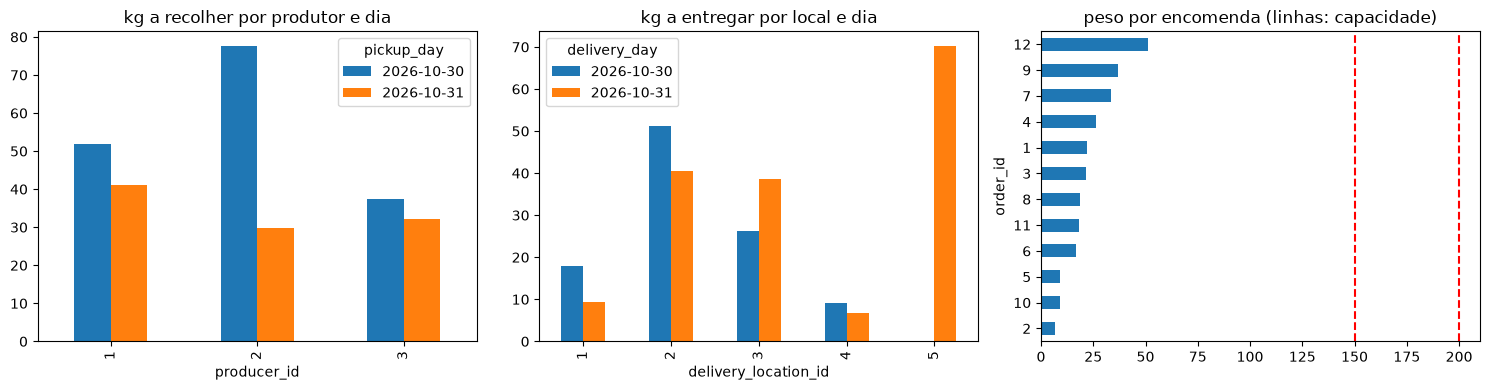

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
oi.pivot_table(index="producer_id", columns="pickup_day", values="weight_kg", aggfunc="sum").plot.bar(ax=axes[0])
axes[0].set_title("kg a recolher por produtor e dia")
oi.pivot_table(index="delivery_location_id", columns="delivery_day", values="weight_kg", aggfunc="sum").plot.bar(ax=axes[1])
axes[1].set_title("kg a entregar por local e dia")
w = oi.groupby("order_id").weight_kg.sum().sort_values()
w.plot.barh(ax=axes[2])
for cap in t["vehicles"].capacity_kg:
    axes[2].axvline(cap, color="red", ls="--")
axes[2].set_title("peso por encomenda (linhas: capacidade)")
fig.tight_layout()

In [9]:
pd.crosstab(oi.pickup_day, oi.delivery_day, values=oi.weight_kg, aggfunc="sum").round(1)

delivery_day,2026-10-30,2026-10-31
pickup_day,,
2026-10-30,104.6,62.3
2026-10-31,NaN,103.1


* Nenhuma encomenda se aproxima da capacidade de um veículo (150 e 200 kg). A capacidade só passa a pesar
  quando se juntam várias recolhas ou entregas na mesma viagem.
* No tiny, os 270 kg do horizonte cabem numa única volta da frota (150 + 200 = 350 kg). Mas no **dia 31**
  há 165 kg para entregar num intervalo curto, e 62 kg deles foram recolhidos no dia 30 e passam a noite
  no armazém. É aí que entra o limite de **24 h** de permanência.
* No `small` o peso total (580 kg) ultrapassa a frota (550 kg), por isso são obrigatórias várias viagens.

## 4. Janelas temporais

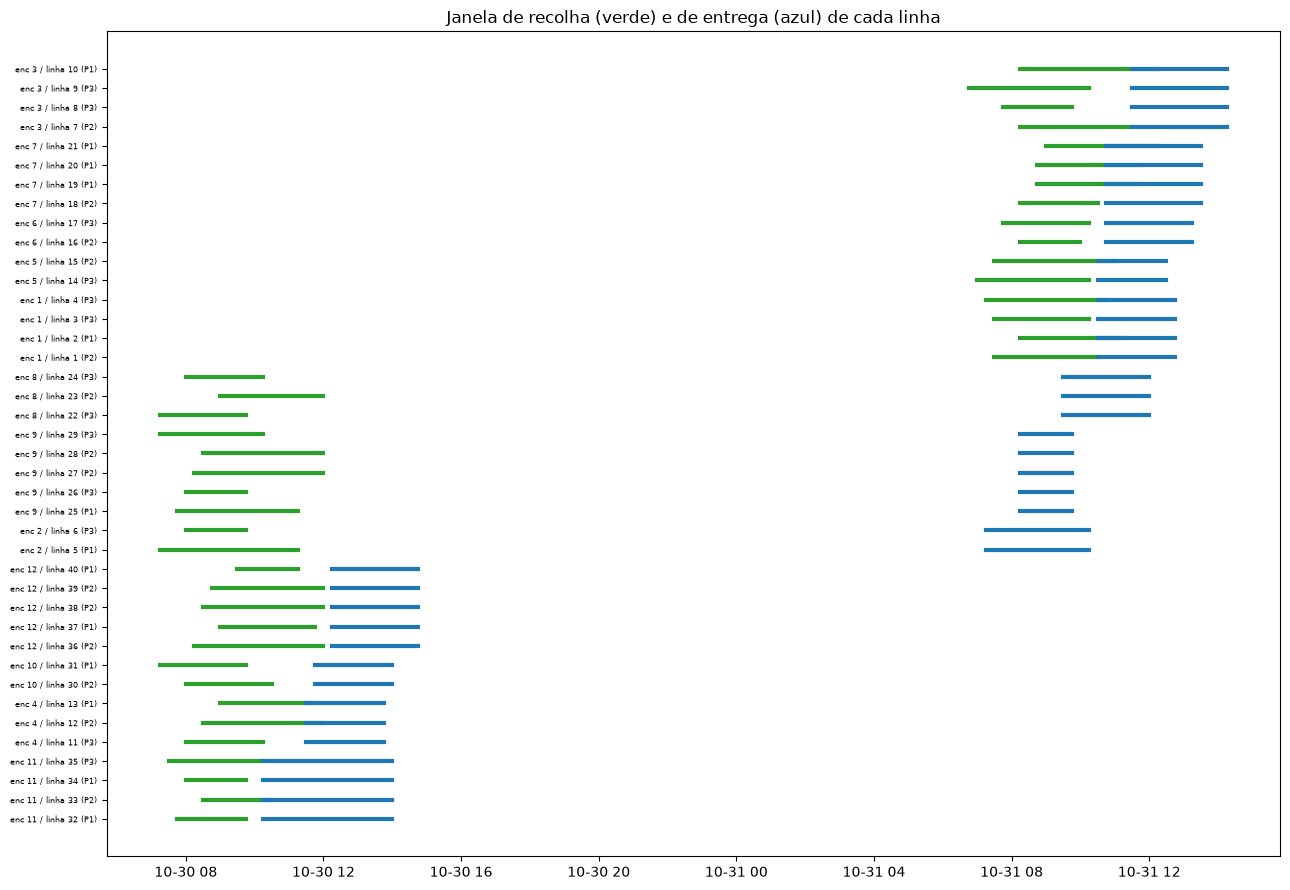

In [10]:
fig, ax = plt.subplots(figsize=(13, 9))
o = oi.sort_values(["delivery_start", "order_id"]).reset_index(drop=True)
for i, r in o.iterrows():
    ax.plot([r.availability_start, r.availability_end], [i, i], color="tab:green", lw=3)
    ax.plot([r.delivery_start, r.delivery_end], [i, i], color="tab:blue", lw=3)
ax.set_yticks(range(len(o)), [f"enc {r.order_id} / linha {r.order_item_id} (P{r.producer_id})" for r in o.itertuples()], fontsize=6)
ax.set_title("Janela de recolha (verde) e de entrega (azul) de cada linha")
fig.tight_layout()

In [11]:
dur = pd.DataFrame({
    "janela recolha (h)": (oi.availability_end - oi.availability_start).dt.total_seconds() / 3600,
    "janela entrega (h)": (oi.delivery_end - oi.delivery_start).dt.total_seconds() / 3600,
    "folga recolha->entrega (h)": (oi.delivery_end - oi.availability_start).dt.total_seconds() / 3600,
})
dur.describe().round(2)

,janela recolha (h),janela entrega (h),folga recolha->entrega (h)
count,40.00,40.00,40.00
mean,2.84,2.49,10.88
std,0.68,0.58,9.23
min,1.75,1.50,4.50
25%,2.25,2.25,5.25
50%,3.00,2.50,6.00
75%,3.50,2.75,11.94
max,4.00,3.75,28.75


In [12]:
# linhas que passam a noite no armazém (recolha num dia, entrega no seguinte)
night = oi[oi.pickup_day != oi.delivery_day]
print(len(night), "linhas atravessam a noite;", night.order_id.nunique(), "encomendas:", sorted(night.order_id.unique()))
gap = (night.delivery_end - night.availability_start).dt.total_seconds() / 3600
print(f"tempo entre abrir a recolha e fechar a entrega: {gap.min():.1f}–{gap.max():.1f} h (limite de permanência: 24 h)")

10 linhas atravessam a noite; 3 encomendas: [np.int64(2), np.int64(8), np.int64(9)]
tempo entre abrir a recolha e fechar a entrega: 25.2–28.8 h (limite de permanência: 24 h)


* Todas as janelas de recolha caem entre as 06:45 e as 12:15, e as de entrega entre as 07:15 e as 14:45.
  As recolhas são de manhã e as entregas a meio do dia.
* Em cada encomenda, todas as linhas têm a mesma janela de entrega. Por isso faz sentido tratar a
  **entrega de uma encomenda** como um único pedido.
* Três encomendas (2, 8 e 9) são recolhidas no dia 30 e entregues no dia 31. Entre abrir a recolha e
  fechar a entrega passam 25 a 29 h, mais do que as 24 h permitidas no armazém. Por isso o horário destas
  encomendas é restringido: recolher muito cedo, ou entregar muito tarde, viola a permanência máxima.

## 5. Geografia e distâncias

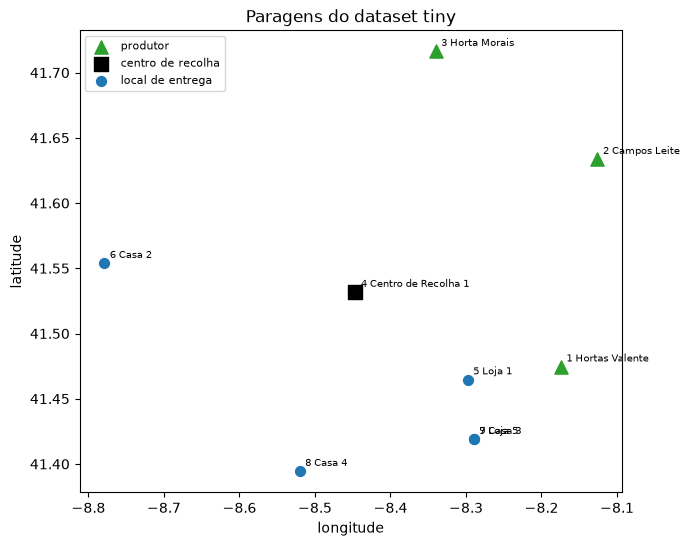

In [13]:
p = load_problem(ROOT / "data" / "tiny")
ax = plot_locations(p)
ax.set_title("Paragens do dataset tiny");

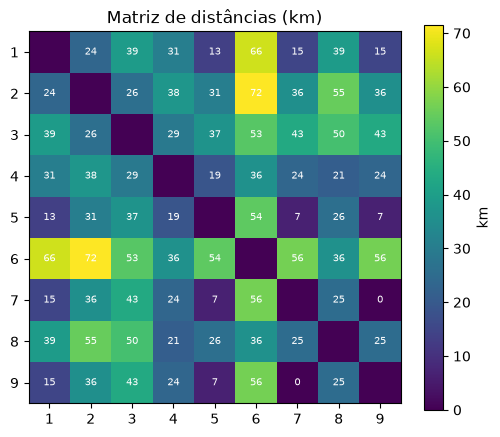

In [14]:
m = t["distance_matrix"].pivot(index="origin_location_id", columns="destination_location_id", values="distance_km")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(m.fillna(0), cmap="viridis")
ax.set_xticks(range(len(m)), m.columns)
ax.set_yticks(range(len(m)), m.index)
for i in range(len(m)):
    for j in range(len(m)):
        v = m.iloc[i, j]
        ax.text(j, i, "" if pd.isna(v) else f"{v:.0f}", ha="center", va="center", fontsize=7, color="white")
fig.colorbar(im, label="km")
ax.set_title("Matriz de distâncias (km)");

In [15]:
dm = t["distance_matrix"]
print("velocidade implícita (km/h):", (dm.distance_km / dm.duration_min * 60).round(1).describe()[["min", "max"]].to_dict())
center = p.depot
print("distância do centro (km):", {b: p.d(center, b) for b in sorted(m.index) if b != center})

velocidade implícita (km/h): {'min': 44.9, 'max': 45.1}
distância do centro (km): {1: 30.6, 2: 37.66, 3: 29.06, 5: 18.79, 6: 36.12, 7: 23.53, 8: 21.39, 9: 23.53}


O centro de recolha (Braga) fica entre os produtores, a leste (Fafe, Vieira do Minho, Terras de Bouro),
e os clientes, a oeste e a sul (Esposende, Famalicão, Guimarães). Cada viagem sai do centro e volta lá, e
cada local fica a 19–38 km do centro, por isso o número de viagens pesa muito no custo total. Os locais 7 e
9 (Casa 3 e Loja 5, em Guimarães) estão no mesmo ponto.

## 6. Pedidos depois do agrupamento

In [16]:
rows = [dict(id=r, tipo=q.kind, local=q.loc, inicio=p.clock(q.tw[0]), fim=p.clock(q.tw[1]),
             kg=q.weight, linhas=len(q.items), depende_de=",".join(q.deps)) for r, q in p.requests.items()]
pd.DataFrame(rows)

,id,tipo,local,inicio,fim,kg,linhas,depende_de
0,P1,P,1,30 09:30,30 09:45,52.0,8,
1,P2,P,1,31 09:00,31 11:15,41.1,5,
2,P3,P,2,30 09:00,30 10:30,77.6,9,
3,P4,P,2,31 08:15,31 10:00,29.9,5,
4,P5,P,3,30 08:00,30 09:45,37.3,7,
5,P6,P,3,31 07:45,31 09:45,32.1,6,
6,D1,D,7,31 10:30,31 12:45,22.0,4,"P2,P4,P6"
7,D2,D,8,31 07:15,31 10:15,6.8,2,"P1,P5"
8,D3,D,6,31 11:30,31 14:15,21.6,4,"P2,P4,P6"
9,D4,D,7,30 11:30,30 13:45,26.3,3,"P1,P3,P5"


Agrupando as linhas do mesmo produtor cujas janelas se intersetam, as 40 linhas do tiny ficam em
**6 recolhas** (3 produtores × 2 dias) e **12 entregas** (uma por encomenda), ou seja, 18 pedidos. As
janelas das recolhas encolhem para a interseção: a P1, por exemplo, fica com apenas 15 min.

## 7. Conclusões da EDA

1. Os dados estão íntegros: não há nada a corrigir.
2. A restrição mais apertada é **temporal** (janelas e encadeamento recolha → armazém → entrega), não de
   capacidade.
3. Cada trajeto passa obrigatoriamente pelo centro, por isso o número de viagens domina o custo.
4. Duas decisões de modelação saem daqui: entregar cada encomenda numa só paragem e agrupar recolhas por
   produtor e janela.